# Model Evaluation and Ablation Comparison

Run the three training notebooks first. They save fraud scores for the six-step validation delay and the final test period. This notebook compares two thresholds selected from the delay/validation scores and reports final test metrics for each.


## 1. Imports and evaluation settings

In [ ]:
import os
import numpy as np
import pandas as pd
from sklearn.metrics import (
    confusion_matrix, f1_score, matthews_corrcoef, precision_recall_curve,
)

RESULTS_DIRS = {
    "Logistic Regression": r"../results/logistic",
    "Random Forest": r"../results/rf",
    "MLP": r"../results/mlp",
}
FEATURE_SET_NAMES = [
    "full", "base_only", "without_balance",
    "without_initiator_activity", "without_recipient_risk",
]
MAX_PREDICTED_FRAUD_RATE = 0.25


## 2. Select thresholds using validation scores

Select the PR-curve threshold on validation data, then evaluate it on the held-out test data.


In [2]:
def find_best_pr_threshold(
    y_true: np.ndarray, scores: np.ndarray
) -> tuple[float, float]:
    """Choose the best PR-curve threshold using validation data."""
    precision, recall, thresholds = precision_recall_curve(y_true, scores)
    if thresholds.size == 0:
        raise ValueError("The validation scores produced no PR-curve thresholds.")

    f1_scores = 2 * (precision[:-1] * recall[:-1]) / (
        precision[:-1] + recall[:-1] + 1e-8
    )
    predicted_fraud_rates = np.array([(scores >= t).mean() for t in thresholds])
    valid = predicted_fraud_rates <= MAX_PREDICTED_FRAUD_RATE

    if valid.any():
        eligible_indices = np.flatnonzero(valid)
        best_idx = eligible_indices[np.argmax(f1_scores[valid])]
    else:
        best_idx = np.argmax(f1_scores)
        print(
            "Warning: all PR-curve thresholds exceed MAX_PREDICTED_FRAUD_RATE; "
            "using uncapped best"
        )

    return float(thresholds[best_idx]), float(f1_scores[best_idx])


def evaluate_model(
    y_true: np.ndarray, scores: np.ndarray, threshold: float
) -> dict[str, float]:
    """Calculate the required metrics for fraud class 1."""
    y_pred = (scores >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    specificity = tn / (tn + fp) if (tn + fp) > 0 else 0.0

    return {
        "Accuracy": (y_true == y_pred).mean(),
        "Precision": tp / (tp + fp) if (tp + fp) > 0 else 0.0,
        "Recall": tp / (tp + fn) if (tp + fn) > 0 else 0.0,
        "Specificity": specificity,
        "F1-Score": f1_score(y_true, y_pred, zero_division=0),
        "MCC": matthews_corrcoef(y_true, y_pred),
    }


## 3. Display final test results


### Hyperparameter ablation: validation comparison and selected test results

Each training study saves validation scores for every tested setting, then writes test scores only for its validation-selected setting. This compares all settings on validation average precision and evaluates the selected setting once on the held-out test period.

In [ ]:
from sklearn.metrics import average_precision_score

HYPERPARAMETER_STUDIES = [
    {"Model": "Logistic Regression", "Study": "C", "Directory": "hyperparameter_ablation", "Prefix": "C"},
    {"Model": "Random Forest", "Study": "min_samples_leaf", "Directory": "hyperparameter_ablation", "Prefix": "min_samples_leaf"},
    {"Model": "Random Forest", "Study": "n_estimators", "Directory": "hyperparameter_ablation_n_estimators", "Prefix": "n_estimators"},
    {"Model": "MLP", "Study": "alpha", "Directory": "hyperparameter_ablation", "Prefix": "alpha"},
    {"Model": "MLP", "Study": "hidden_layer_size", "Directory": "hyperparameter_ablation_hidden_layer_sizes", "Prefix": "hidden_layer_size"},
]

hyperparameter_validation_rows = []
hyperparameter_test_rows = []

for study in HYPERPARAMETER_STUDIES:
    study_dir = os.path.join(RESULTS_DIRS[study["Model"]], study["Directory"])
    selected_validation_path = os.path.join(study_dir, "selected_validation.pkl")
    selected_test_path = os.path.join(study_dir, "selected_test.pkl")
    if not os.path.isdir(study_dir):
        raise FileNotFoundError(f"Missing hyperparameter results for {study['Model']} / {study['Study']}: {study_dir}")
    if not os.path.isfile(selected_validation_path) or not os.path.isfile(selected_test_path):
        raise FileNotFoundError(f"Missing selected validation/test scores for {study['Model']} / {study['Study']}")

    candidate_paths = sorted(
        os.path.join(study_dir, filename)
        for filename in os.listdir(study_dir)
        if filename.endswith("_validation.pkl") and filename != "selected_validation.pkl"
    )
    if not candidate_paths:
        raise FileNotFoundError(f"No candidate validation scores found for {study['Model']} / {study['Study']}")

    selected_validation_df = pd.read_pickle(selected_validation_path)
    selected_y = selected_validation_df["isFraud"].to_numpy()
    selected_scores = selected_validation_df["score"].to_numpy()
    selected_candidates = []

    for candidate_path in candidate_paths:
        filename = os.path.basename(candidate_path)
        setting = filename[:-len("_validation.pkl")]
        prefix = f"{study['Prefix']}_"
        if not setting.startswith(prefix):
            raise ValueError(f"Unexpected validation artifact for {study['Model']} / {study['Study']}: {filename}")

        raw_value = setting[len(prefix):]
        numeric_value = float(raw_value)
        parameter_value = int(numeric_value) if numeric_value.is_integer() else numeric_value
        validation_df = pd.read_pickle(candidate_path)
        y_validation = validation_df["isFraud"].to_numpy()
        validation_scores = validation_df["score"].to_numpy()
        validation_ap = average_precision_score(y_validation, validation_scores)
        validation_threshold, validation_f1 = find_best_pr_threshold(y_validation, validation_scores)
        is_selected = (
            np.array_equal(y_validation, selected_y)
            and np.array_equal(validation_scores, selected_scores)
        )
        if is_selected:
            selected_candidates.append((parameter_value, validation_ap, validation_f1))

        hyperparameter_validation_rows.append({
            "Model": study["Model"],
            "Study": study["Study"],
            "Parameter Value": parameter_value,
            "Validation AP": validation_ap,
            "Validation F1": validation_f1,
            "Selected": is_selected,
        })

    if len(selected_candidates) != 1:
        raise ValueError(
            f"Expected one candidate matching the selected validation scores for "
            f"{study['Model']} / {study['Study']}; found {len(selected_candidates)}"
        )

    selected_value, selected_ap, selected_f1 = selected_candidates[0]
    threshold, _ = find_best_pr_threshold(selected_y, selected_scores)
    selected_test_df = pd.read_pickle(selected_test_path)
    test_metrics = evaluate_model(
        selected_test_df["isFraud"].to_numpy(),
        selected_test_df["score"].to_numpy(),
        threshold,
    )
    hyperparameter_test_rows.append({
        "Model": study["Model"],
        "Study": study["Study"],
        "Selected Value": selected_value,
        "Validation AP": selected_ap,
        "Threshold": threshold,
        "Validation F1": selected_f1,
        **test_metrics,
    })

hyperparameter_validation_results_df = pd.DataFrame(hyperparameter_validation_rows)
hyperparameter_validation_results_df.sort_values(
    ["Model", "Study", "Validation AP"], ascending=[True, True, False]
).reset_index(drop=True)

In [ ]:
hyperparameter_test_results_df = pd.DataFrame(hyperparameter_test_rows)
hyperparameter_test_results_df[[
    "Model", "Study", "Selected Value", "Validation AP", "Threshold", "Validation F1",
    "Accuracy", "Precision", "Recall", "Specificity", "F1-Score", "MCC",
]]

### Feature ablation: validation comparison and selected test results

In [16]:
# Select each threshold from validation data and evaluate once on the test data.
results = []

for model_name, model_dir in RESULTS_DIRS.items():
    if not os.path.isdir(model_dir):
        raise FileNotFoundError(f"Run the {model_name} training notebook first: {model_dir}")

    for feature_set_name in FEATURE_SET_NAMES:
        validation_path = os.path.join(model_dir, f"{feature_set_name}_validation.pkl")
        test_path = os.path.join(model_dir, f"{feature_set_name}_test.pkl")
        if not os.path.isfile(validation_path) or not os.path.isfile(test_path):
            raise FileNotFoundError(f"Missing saved scores for {model_name} / {feature_set_name}")

        validation_df = pd.read_pickle(validation_path)
        test_df = pd.read_pickle(test_path)
        threshold, validation_f1 = find_best_pr_threshold(
            validation_df["isFraud"].to_numpy(), validation_df["score"].to_numpy()
        )
        metrics = evaluate_model(
            test_df["isFraud"].to_numpy(), test_df["score"].to_numpy(), threshold
        )
        results.append({
            "Model": model_name,
            "Feature Set": feature_set_name,
            "Threshold": threshold,
            "Validation F1": validation_f1,
            **metrics,
        })

results_df = pd.DataFrame(results)
results_df[[
    "Model", "Feature Set", "Threshold", "Validation F1",
    "Accuracy", "Precision", "Recall", "Specificity", "F1-Score", "MCC",
]]

,Model,Feature Set,Threshold,Validation F1,Accuracy,Precision,Recall,Specificity,F1-Score,MCC
0,Logistic Regression,full,0.808353,0.409954,0.856856,0.314454,0.468394,0.896303,0.376289,0.306534
1,Logistic Regression,base_only,0.807649,0.409820,0.851339,0.314640,0.519937,0.884992,0.392038,0.325985
2,Logistic Regression,without_balance,0.808178,0.410195,0.857380,0.315428,0.467464,0.896976,0.376684,0.306972
3,Logistic Regression,without_initiator_activity,0.805100,0.409912,0.850989,0.314409,0.522120,0.884385,0.392477,0.326594
4,Logistic Regression,without_recipient_risk,0.811340,0.411034,0.854843,0.315453,0.491087,0.891782,0.384147,0.315919
5,Random Forest,full,0.671679,0.410742,0.844429,0.312898,0.574916,0.871798,0.405243,0.344530
6,Random Forest,base_only,0.697808,0.406867,0.842047,0.313104,0.597573,0.866873,0.410908,0.352861
7,Random Forest,without_balance,0.670041,0.407437,0.845000,0.314007,0.575166,0.872401,0.406234,0.345615
8,Random Forest,without_initiator_activity,0.696790,0.409683,0.841760,0.312284,0.595998,0.866716,0.409830,0.351548
9,Random Forest,without_recipient_risk,0.672694,0.404984,0.844413,0.311168,0.566648,0.872619,0.401731,0.339996


## 4. Discovery


Run the setup cell first, then each plot cell separately. All thresholds are selected using the validation PR curve; test-set plots are for final descriptive analysis only and should not be used to retune thresholds.


In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, precision_recall_curve

# Thresholds are selected on validation data; test plots are descriptive only.
discovery_data = {}
for model_name, model_dir in RESULTS_DIRS.items():
    for feature_set_name in FEATURE_SET_NAMES:
        key = (model_name, feature_set_name)
        validation_path = os.path.join(model_dir, f"{feature_set_name}_validation.pkl")
        test_path = os.path.join(model_dir, f"{feature_set_name}_test.pkl")
        if not os.path.isfile(validation_path) or not os.path.isfile(test_path):
            raise FileNotFoundError(f"Missing scores for {model_name} / {feature_set_name}")

        validation_df = pd.read_pickle(validation_path)
        test_df = pd.read_pickle(test_path)
        rows = results_df[
            (results_df["Model"] == model_name)
            & (results_df["Feature Set"] == feature_set_name)
        ]
        if len(rows) != 1:
            raise ValueError(f"Expected one PR-curve threshold for {model_name} / {feature_set_name}; found {len(rows)}")

        discovery_data[key] = {
            "y_validation": validation_df["isFraud"].to_numpy(),
            "validation_scores": validation_df["score"].to_numpy(),
            "y_test": test_df["isFraud"].to_numpy(),
            "test_scores": test_df["score"].to_numpy(),
            "threshold": float(rows.iloc[0]["Threshold"]),
        }

print(f"Loaded PR-curve results for {len(discovery_data)} model/feature-set pairs.")

Loaded PR-curve results for 15 model/feature-set pairs.


### Precision recall curves

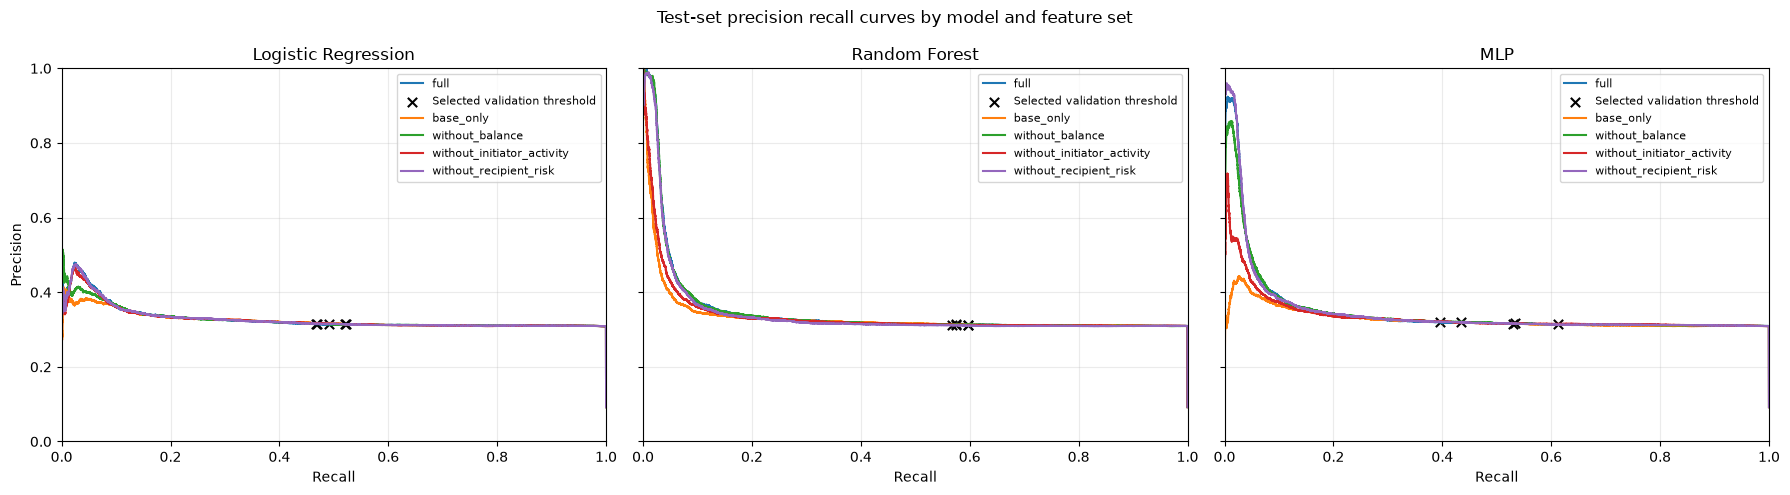

In [22]:
fig, axes = plt.subplots(1, len(RESULTS_DIRS), figsize=(18, 5), sharex=True, sharey=True)
if len(RESULTS_DIRS) == 1:
    axes = [axes]

for ax, model_name in zip(axes, RESULTS_DIRS):
    for feature_set_index, feature_set_name in enumerate(FEATURE_SET_NAMES):
        data = discovery_data[(model_name, feature_set_name)]
        precision, recall, _ = precision_recall_curve(data["y_test"], data["test_scores"])
        ax.plot(recall, precision, label=feature_set_name)

        threshold = data["threshold"]
        y_pred = (data["test_scores"] >= threshold).astype(int)
        tp = np.sum((data["y_test"] == 1) & (y_pred == 1))
        fp = np.sum((data["y_test"] == 0) & (y_pred == 1))
        fn = np.sum((data["y_test"] == 1) & (y_pred == 0))
        point_precision = tp / (tp + fp) if tp + fp else 0.0
        point_recall = tp / (tp + fn) if tp + fn else 0.0
        ax.scatter(
            point_recall, point_precision, s=45, marker="x", color="black",
            label="Selected validation threshold" if feature_set_index == 0 else None,
        )

    ax.set_title(model_name)
    ax.set_xlabel("Recall")
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.grid(alpha=0.25)
    ax.legend(fontsize=8)
axes[0].set_ylabel("Precision")
fig.suptitle("Test-set precision recall curves by model and feature set")
fig.tight_layout()
plt.show()

### Confusion matrices at the selected threshold

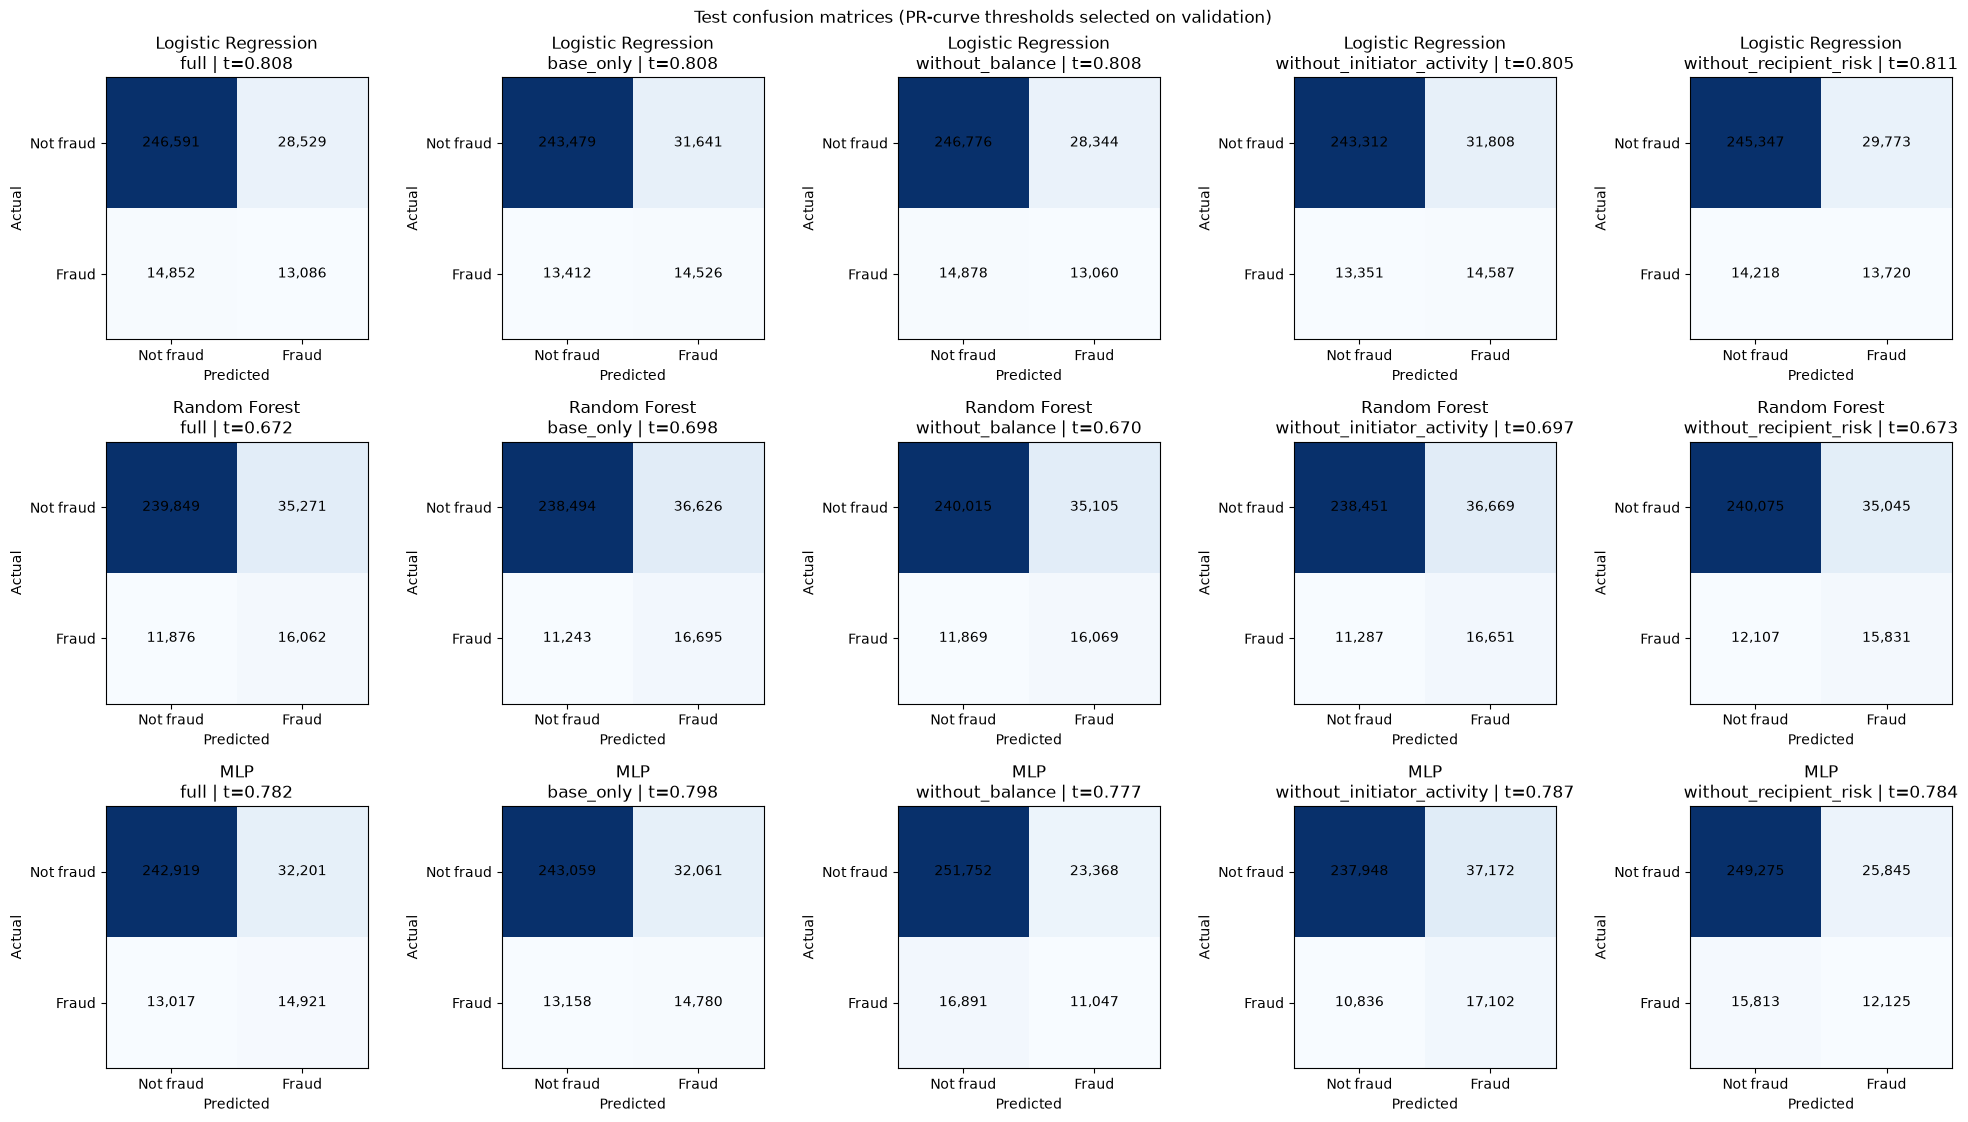

In [19]:
fig, axes = plt.subplots(
    len(RESULTS_DIRS), len(FEATURE_SET_NAMES),
    figsize=(4 * len(FEATURE_SET_NAMES), 3.8 * len(RESULTS_DIRS)),
    squeeze=False,
)

for row, model_name in enumerate(RESULTS_DIRS):
    for col, feature_set_name in enumerate(FEATURE_SET_NAMES):
        ax = axes[row, col]
        data = discovery_data[(model_name, feature_set_name)]
        threshold = data["threshold"]
        y_pred = (data["test_scores"] >= threshold).astype(int)
        cm = confusion_matrix(data["y_test"], y_pred, labels=[0, 1])
        ax.imshow(cm, cmap="Blues")
        for (i, j), count in np.ndenumerate(cm):
            ax.text(j, i, f"{count:,}", ha="center", va="center", color="black")
        ax.set_xticks([0, 1], labels=["Not fraud", "Fraud"])
        ax.set_yticks([0, 1], labels=["Not fraud", "Fraud"])
        ax.set_xlabel("Predicted")
        ax.set_ylabel("Actual")
        ax.set_title(f"{model_name}\n{feature_set_name} | t={threshold:.3f}")

fig.suptitle("Test confusion matrices (PR-curve thresholds selected on validation)")
fig.tight_layout()
plt.show()

### Metric comparison across models and feature sets

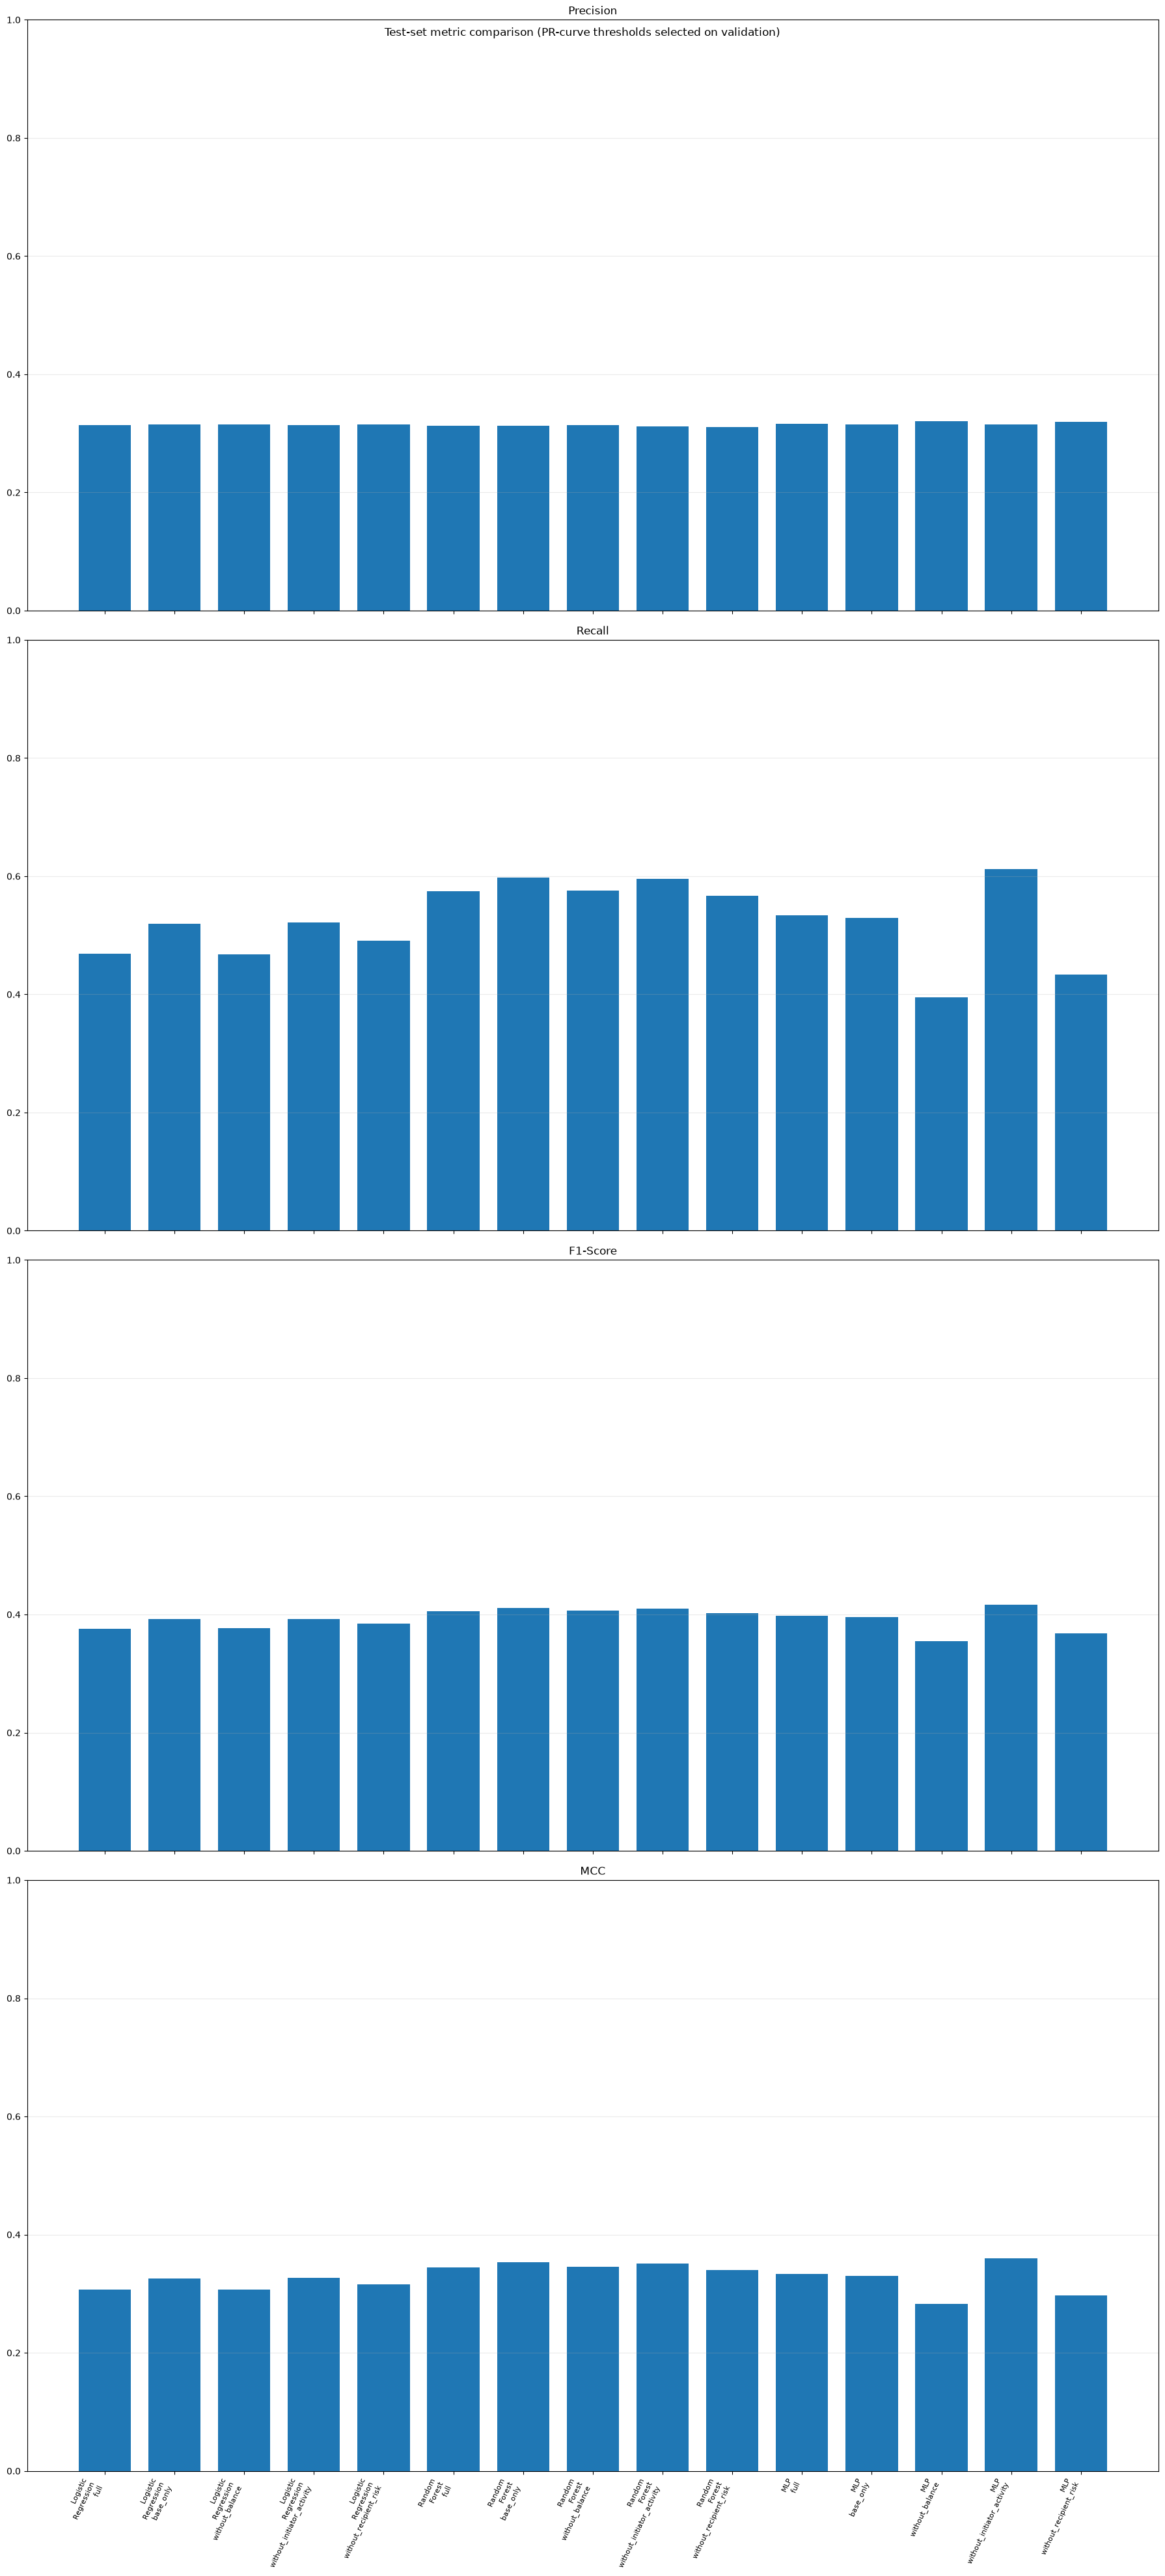

In [29]:
metrics_to_plot = ["Precision", "Recall", "F1-Score", "MCC"]
plot_df = results_df.copy()
plot_df["Configuration"] = (
    plot_df["Model"].str.replace(" ", "\n", regex=False)
    + "\n" + plot_df["Feature Set"]
)
configurations = list(dict.fromkeys(plot_df["Configuration"]))
x = np.arange(len(configurations))

fig, axes = plt.subplots(4, 1, figsize=(18, 40), sharex=True)
for ax, metric in zip(axes.flat, metrics_to_plot):
    values = plot_df.set_index("Configuration").reindex(configurations)[metric].to_numpy(dtype=float)
    ax.bar(x, values, width=0.75)
    ax.set_title(metric)
    ax.set_ylim(0, 1)
    ax.grid(axis="y", alpha=0.25)
    ax.set_xticks(x, labels=configurations, rotation=65, ha="right", fontsize=8)
fig.suptitle("Test-set metric comparison (PR-curve thresholds selected on validation)")
fig.tight_layout()
plt.show()

### Validation-to-test predicted fraud rate

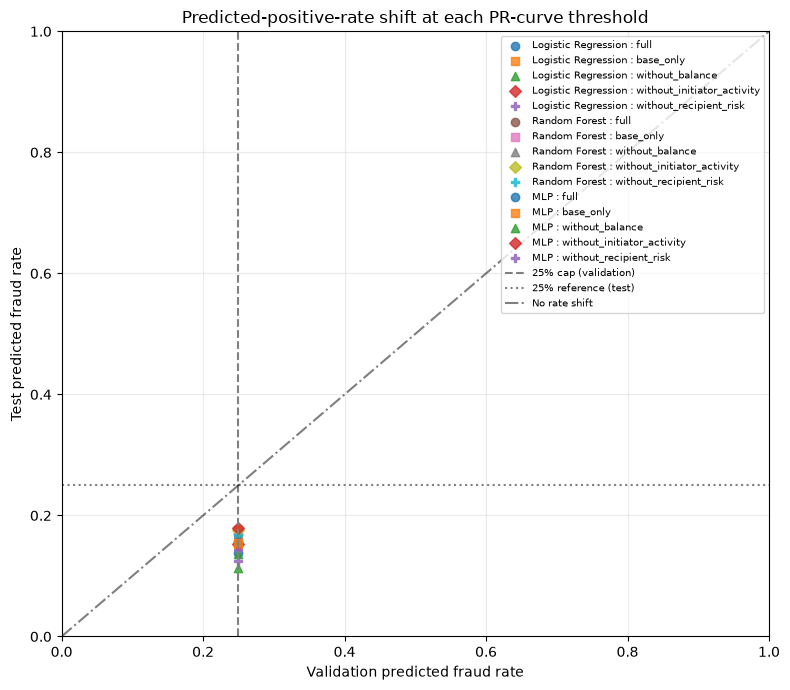

In [30]:
fig, ax = plt.subplots(figsize=(8, 7))
markers = ["o", "s", "^", "D", "P"]

for model_name in RESULTS_DIRS:
    for feature_index, feature_set_name in enumerate(FEATURE_SET_NAMES):
        data = discovery_data[(model_name, feature_set_name)]
        threshold = data["threshold"]
        validation_rate = (data["validation_scores"] >= threshold).mean()
        test_rate = (data["test_scores"] >= threshold).mean()
        ax.scatter(
            validation_rate, test_rate,
            marker=markers[feature_index % len(markers)],
            label=f"{model_name} : {feature_set_name}", alpha=0.8,
        )

ax.axvline(MAX_PREDICTED_FRAUD_RATE, color="gray", linestyle="--", label="25% cap (validation)")
ax.axhline(MAX_PREDICTED_FRAUD_RATE, color="gray", linestyle=":", label="25% reference (test)")
ax.plot([0, 1], [0, 1], color="black", linestyle="-.", alpha=0.5, label="No rate shift")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.set_xlabel("Validation predicted fraud rate")
ax.set_ylabel("Test predicted fraud rate")
ax.set_title("Predicted-positive-rate shift at each PR-curve threshold")
ax.grid(alpha=0.25)
ax.legend(fontsize=7, loc="best")
fig.tight_layout()
plt.show()